In [1]:
import sys; sys.path.append("..")
import numpy as np, matplotlib.pyplot as plt
from data import get_splits
from metrics import evaluate, Timer
from naive_bayes import MultinomialNB, BernoulliNB
d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]

results = {}
for name, cls in [("Multinomial", MultinomialNB), ("Bernoulli", BernoulliNB)]:
    with Timer() as t_fit:
        m = cls(alpha=1.0).fit(Xtr, ytr)
    with Timer() as t_pred:
        p_va = m.predict(Xva)
    p_tr = m.predict(Xtr)
    r_tr, r_va = evaluate(ytr, p_tr), evaluate(yva, p_va)
    results[name] = (r_tr, r_va, t_fit.seconds, t_pred.seconds)
    print(f"{name}: train {r_tr['accuracy']*100:.2f}% | val {r_va['accuracy']*100:.2f}% | "
          f"F1 val {r_va['f1_macro']*100:.2f}% | fit {t_fit.seconds:.3f}s | predict {t_pred.seconds:.3f}s")

Multinomial: train 82.45% | val 82.29% | F1 val 82.11% | fit 5.649s | predict 0.023s
Bernoulli: train 83.63% | val 83.36% | F1 val 83.13% | fit 2.491s | predict 0.025s


Multinomial [np.float64(82.38), np.float64(82.38), np.float64(82.37), np.float64(82.33), np.float64(82.31), np.float64(82.29), np.float64(82.22), np.float64(82.19), np.float64(82.06)]
Bernoulli [np.float64(83.52), np.float64(83.53), np.float64(83.52), np.float64(83.51), np.float64(83.47), np.float64(83.36), np.float64(83.3), np.float64(83.25), np.float64(83.12)]


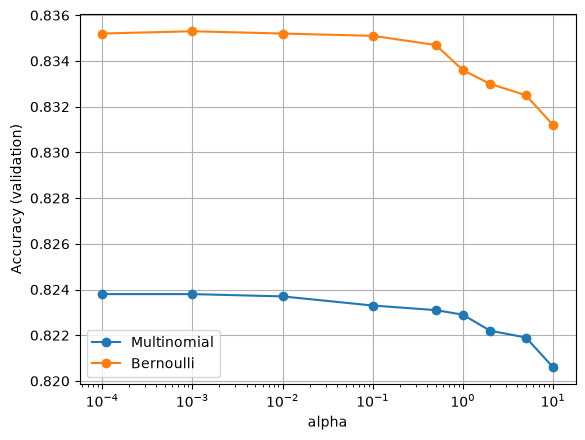

In [2]:
grid = [1e-4, 1e-3, 1e-2, 1e-1, 0.5, 1, 2, 5, 10]
curves = {}
for name, cls in [("Multinomial", MultinomialNB), ("Bernoulli", BernoulliNB)]:
    curves[name] = [evaluate(yva, cls(alpha=a).fit(Xtr, ytr).predict(Xva))["accuracy"] for a in grid]
    print(name, [round(v * 100, 2) for v in curves[name]])

plt.figure()
for name, accs in curves.items():
    plt.semilogx(grid, accs, "o-", label=name)
plt.xlabel("alpha"); plt.ylabel("Accuracy (validation)"); plt.legend(); plt.grid(True)
plt.savefig("../report/nb_alpha.png", dpi=150); plt.show()

In [3]:
best = {n: grid[int(np.argmax(c))] for n, c in curves.items()}
print("alpha tốt nhất:", best)
for name, cls in [("Multinomial", MultinomialNB), ("Bernoulli", BernoulliNB)]:
    r = evaluate(yva, cls(alpha=best[name]).fit(Xtr, ytr).predict(Xva))
    print(f"{name} (alpha={best[name]}): val acc {r['accuracy']*100:.2f}% | F1 {r['f1_macro']*100:.2f}%")

alpha tốt nhất: {'Multinomial': 0.0001, 'Bernoulli': 0.001}
Multinomial (alpha=0.0001): val acc 82.38% | F1 82.21%
Bernoulli (alpha=0.001): val acc 83.53% | F1 83.29%


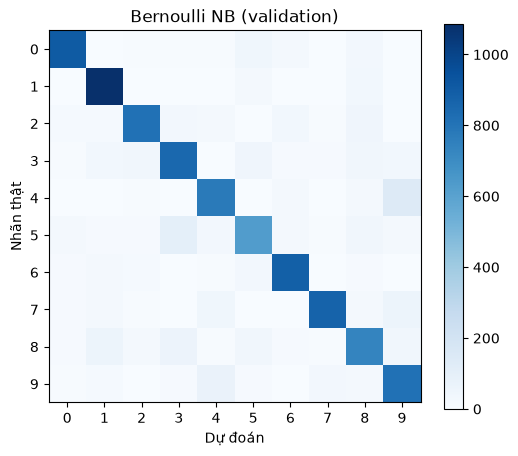

In [4]:
best_name = max(curves, key=lambda n: max(curves[n]))
cls = MultinomialNB if best_name == "Multinomial" else BernoulliNB
r = evaluate(yva, cls(alpha=best[best_name]).fit(Xtr, ytr).predict(Xva))
plt.figure(figsize=(6, 5)); plt.imshow(r["confusion_matrix"], cmap="Blues"); plt.colorbar()
plt.xlabel("Dự đoán"); plt.ylabel("Nhãn thật"); plt.xticks(range(10)); plt.yticks(range(10))
plt.title(f"{best_name} NB (validation)")
plt.savefig("../report/nb_confusion_val.png", dpi=150); plt.show()